# Example 13.3: Hybrid GA + ANN Synthesis – Intelligent Population Initialization
**Chapter 13 – Neural Networks for Four-Bar Linkage Synthesis**

Compares pure GA vs. hybrid GA (initialized with ANN candidates).

Metric                           Pure GA   Hybrid GA
Final Hausdorff Error (mm)         28.79       28.12
1st gen. with error < 5mm            N/A         N/A
  Pure GA:    [ 27.7 130.   30. ]
  Hybrid GA:  [ 28.3 130.   30. ]


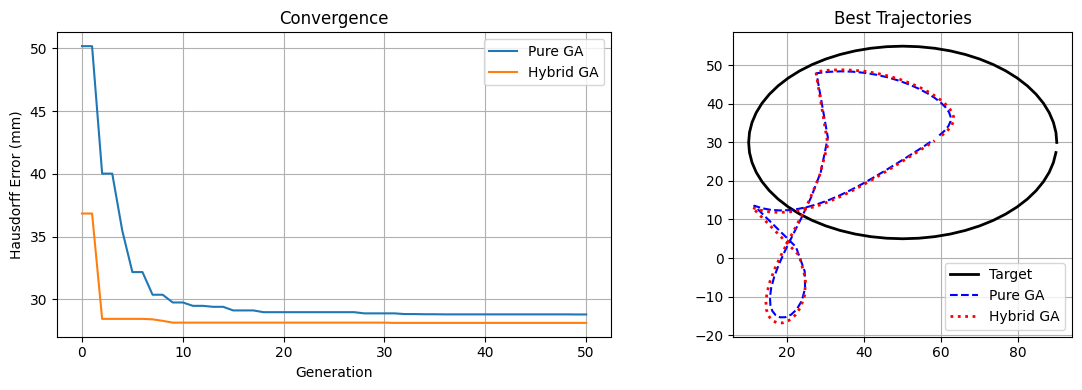

Figure saved: hybrid_ga_convergence.png


In [2]:
from numpy import *
import matplotlib.pyplot as plt

random.seed(2024)
D_FIXED=85.; LP,DELTA=45.,pi/4; N_TH=60

def curve(a,b,c,n=N_TH):
    d=D_FIXED; ths=linspace(0,2*pi,n,endpoint=False)
    xs,ys=zeros(n),zeros(n)
    for i,th2 in enumerate(ths):
        x2=a*cos(th2)-d; y2=a*sin(th2)
        r=sqrt(x2**2+y2**2)
        arg=clip((r**2+c**2-b**2)/(2*r*c),-1,1)
        th3=arctan2(y2,x2)+arccos(arg)
        xs[i]=a*cos(th2)+LP*cos(th3+DELTA); ys[i]=a*sin(th2)+LP*sin(th3+DELTA)
    return xs,ys

def hausdorff(xs,ys,xt,yt):
    P=column_stack([xs,ys]); T=column_stack([xt,yt])
    D=sqrt(((P[:,None,:]-T[None,:,:])**2).sum(2))
    return maximum(D.min(1).max(),D.min(0).max())

def fitness(ind,xt,yt):
    try:
        xs,ys=curve(*ind)
        return 1e6 if any(isnan(xs)) else hausdorff(xs,ys,xt,yt)
    except: return 1e6

t=linspace(0,2*pi,N_TH,endpoint=False)
xt=50+40*cos(t); yt=30+25*sin(t)

def ga(pop_ini,n_gen=50,pc=0.85,pm=0.12):
    pop=pop_ini.copy(); n,d=pop.shape
    LB=array([20.,30.,30.]); UB=array([100.,130.,130.])
    fit=array([fitness(p,xt,yt) for p in pop]); hist=[fit.min()]
    for _ in range(n_gen):
        idx_p=array([argmin(fit[random.choice(n,3,replace=False)]) for __ in range(n)])
        parents=pop[idx_p]; alpha=0.5
        pairs=random.permutation(n).reshape(-1,2); offspring=pop.copy()
        for i,j in pairs:
            if random.rand()<pc:
                lo=minimum(parents[i],parents[j])-alpha*abs(parents[i]-parents[j])
                hi=maximum(parents[i],parents[j])+alpha*abs(parents[i]-parents[j])
                offspring[i]=clip(random.uniform(lo,hi),LB,UB)
                offspring[j]=clip(random.uniform(lo,hi),LB,UB)
        mask=random.rand(n,d)<pm; offspring+=mask*random.randn(n,d)*5.
        offspring=clip(offspring,LB,UB)
        fit_off=array([fitness(p,xt,yt) for p in offspring])
        best_prev=argmin(fit); offspring[0]=pop[best_prev]; fit_off[0]=fit[best_prev]
        pop,fit=offspring,fit_off; hist.append(fit.min())
    return pop[argmin(fit)],hist

def ann_candidates(xt,yt,k=8):
    sx,sy=std(xt)+1e-6,std(yt)+1e-6
    a_est=clip(sx*0.9,20,90); b_est=clip(sy*1.3,30,120); c_est=clip((sx+sy)*0.7,30,110)
    cands=array([a_est,b_est,c_est])+random.randn(k,3)*array([5.,8.,8.])
    return clip(cands,[20,30,30],[100,130,130])

N_POP,N_GEN=20,50
pop_r=random.uniform([20,30,30],[100,130,130],(N_POP,3))
best_pure,hist_pure=ga(pop_r,n_gen=N_GEN)
pop_ann=ann_candidates(xt,yt,k=8)
pop_h=vstack([pop_ann,random.uniform([20,30,30],[100,130,130],(N_POP-8,3))])
best_h,hist_h=ga(pop_h,n_gen=N_GEN)

print("="*52)
print(f"{'Metric':30s}  {'Pure GA':>8}  {'Hybrid GA':>10}")
print("="*52)
print(f"{'Final Hausdorff Error (mm)':30s}  {hist_pure[-1]:8.2f}  {hist_h[-1]:10.2f}")
def gen_threshold(h,u=5.): idx=where(array(h)<u)[0]; return int(idx[0]) if len(idx)>0 else -1
gp=gen_threshold(hist_pure); gh=gen_threshold(hist_h)
print(f"{'1st gen. with error < 5mm':30s}  {gp if gp>=0 else 'N/A':>8}  {gh if gh>=0 else 'N/A':>10}")
print(f"  Pure GA:    {best_pure.round(1)}")
print(f"  Hybrid GA:  {best_h.round(1)}")
print("="*52)

# Visualization
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(hist_pure, label='Pure GA'); axes[0].plot(hist_h, label='Hybrid GA')
axes[0].set_xlabel('Generation'); axes[0].set_ylabel('Hausdorff Error (mm)')
axes[0].set_title('Convergence'); axes[0].legend(); axes[0].grid(True)
axes[1].plot(xt,yt,'k-',lw=2,label='Target')
xs_p,ys_p=curve(*best_pure); axes[1].plot(xs_p,ys_p,'b--',label='Pure GA')
xs_h,ys_h=curve(*best_h); axes[1].plot(xs_h,ys_h,'r:',lw=2,label='Hybrid GA')
axes[1].set_title('Best Trajectories'); axes[1].legend(); axes[1].grid(True); axes[1].set_aspect('equal')
plt.tight_layout(); plt.savefig('hybrid_ga_convergence.png',dpi=150); plt.show()
print("Figure saved: hybrid_ga_convergence.png")